# Checkpoint 05 – Classificação de imagens: Homer x Bart

**FIAP – Redes Neurais Artificiais e Deep Learning**

**Aluno(a):** Bruno Henrique Ferreira Ambrosio | **RM:** 571218

---

Neste checkpoint usei como base o notebook da Aula 4 (Transfer Learning com VGG16 – Gatos vs Cachorros) e adaptei para o dataset de personagens dos Simpsons. O código é o mesmo da aula. Mudei o dataset, o nome das classes, a extensão das imagens (que aqui são `.bmp`) e alguns hiperparâmetros, que explico ao longo do notebook.

Para facilitar a leitura, deixei cada etapa pedida no enunciado marcada:

| Etapa | Onde está |
|---|---|
| 1. Definição do problema | logo abaixo |
| 2. Pré-processamento das imagens | Etapa 2 e seções 3 e 4 |
| 3. Arquitetura da CNN | Etapa 3 e seções 5 a 7 |
| 4. Percentual de acerto | Seção 8 |
| 5. Imagem da internet | Seção 9 |

---

## Etapa 1 – Definição do problema

O objetivo é treinar uma rede neural convolucional que, ao receber a imagem de um personagem dos Simpsons, diga se é o **Homer** ou o **Bart**. É um problema de **classificação binária de imagens** com aprendizado supervisionado: cada imagem já vem rotulada pela pasta em que está (`bart/` ou `homer/`).

O dataset está dividido assim:

| Conjunto | Bart | Homer | Total |
|---|---|---|---|
| `training_set` | 118 | 78 | 196 |
| `test_set` | 42 | 31 | 73 |

Alguns pontos pesaram nas minhas escolhas:

- **O dataset é bem pequeno.** São 196 imagens de treino, enquanto no exemplo de gatos e cachorros da aula eram 8.000. Com tão poucas imagens, uma CNN treinada do zero tende a decorar o treino. Por isso segui a dica do enunciado e usei Transfer Learning com a VGG16.
- **As classes não estão balanceadas.** Há mais Bart (~60%) do que Homer (~40%). Se o modelo chutasse "Bart" para tudo, já acertaria 42 das 73 imagens do teste (57,5%). Esse é o mínimo que a rede precisa superar para mostrar que realmente aprendeu alguma coisa.
- As imagens estão em `.bmp` e têm tamanhos diferentes, com poses e fundos variados.

A entrada da rede é a imagem RGB e a saída é a probabilidade de ser o Homer (sigmoid). Acima de 0,5 a imagem é classificada como Homer, e abaixo como Bart. Para medir o desempenho uso a **acurácia no test_set**, e também olho a matriz de confusão para ver se a rede erra mais uma classe do que a outra.

Testei duas configurações, que são as duas fases vistas na aula:
- **Configuração 1 – Feature Extraction:** a VGG16 fica congelada e só a cabeça nova é treinada.
- **Configuração 2 – Fine-Tuning:** partindo da configuração 1, libero o bloco 5 da VGG16 e continuo o treino com um learning rate bem menor.

## 📚 Revisão Teórica: O que é Transfer Learning

### O problema de treinar do zero

Uma CNN precisa aprender, camada a camada, a detectar bordas → texturas → partes (olhos, orelhas) → objetos. No nosso caso o problema é ainda maior: temos só 196 imagens de treino de Homer e Bart. Treinar uma CNN do zero com tão poucas imagens leva a overfitting.

### A ideia

Redes treinadas no **ImageNet** (1,2 milhão de imagens, 1.000 classes, com contornos, cores, texturas e formas variadas) já aprenderam filtros genéricos de altíssima qualidade. Em vez de aprender tudo de novo, nós:

1. **Reaproveitamos as camadas convolucionais** já treinadas (a "base")
2. **Trocamos apenas a cabeça** (as camadas densas de saída) por uma nova, adequada ao nosso problema binário
3. Treinamos essa cabeça nova com os nossos dados

### As duas estratégias que vamos usar

| Estratégia | O que treina | Learning rate | Quando usar |
|-----------|--------------|---------------|-------------|
| **Feature Extraction** | Só a cabeça nova; base 100% congelada | Normal (na aula 1e-4; aqui usei 1e-3) | Sempre primeiro. Rápido, estável |
| **Fine-Tuning** | Cabeça + últimos blocos da base | Muito baixo (1e-5) | Depois da cabeça convergir, para ganhar mais alguns pontos |

⚠️ **Por que o learning rate precisa ser baixo no fine-tuning?** Os pesos da VGG16 já são bons. Um LR alto destrói esses pesos nas primeiras iterações (a cabeça, recém-criada, gera gradientes grandes e ruidosos). Por isso a ordem importa: primeiro a cabeça converge com a base congelada, só depois descongelamos.

---


## 📚 Revisão Teórica: A Arquitetura VGG16

Proposta por Simonyan & Zisserman (Oxford, 2014). O "16" indica **16 camadas com pesos**: 13 convolucionais + 3 densas.

```
Input (224×224×3)
    ↓
Bloco 1: Conv(64)  → Conv(64)              → MaxPool   → (112×112×64)
Bloco 2: Conv(128) → Conv(128)             → MaxPool   → (56×56×128)
Bloco 3: Conv(256) → Conv(256) → Conv(256) → MaxPool   → (28×28×256)
Bloco 4: Conv(512) → Conv(512) → Conv(512) → MaxPool   → (14×14×512)
Bloco 5: Conv(512) → Conv(512) → Conv(512) → MaxPool   → (7×7×512)
    ↓
[ Flatten → Dense(4096) → Dense(4096) → Dense(1000, softmax) ]   ← cabeça original (ImageNet)
```

Todas as convoluções são **3×3 com padding 'same'** (a dimensão só cai no MaxPool 2×2). Compare com a Aula 3, onde usamos convolução sem padding (64 → 62 → 31 → 29 → 14).

### O que vamos usar

- `include_top=False`: descartamos a cabeça original (colchetes acima). Ficamos só com os 5 blocos convolucionais, saída `(7, 7, 512)`
- `weights='imagenet'`: carregamos os pesos já treinados (~58 MB de download na primeira vez)
- Nossa cabeça nova: `GlobalAveragePooling2D → Dense(256) → Dropout(0.5) → Dense(1, sigmoid)`

### Por que GlobalAveragePooling em vez de Flatten?

`Flatten` de `(7,7,512)` gera 25.088 valores; uma `Dense(256)` em cima teria 6,4 milhões de parâmetros só nessa camada. `GlobalAveragePooling2D` tira a média espacial de cada um dos 512 mapas → vetor de 512, e a `Dense(256)` fica com ~131 mil parâmetros. Menos parâmetros, menos overfitting, e é o padrão em transfer learning.

---


## 📚 Revisão Teórica: O Pré-processamento MUDA (ponto crítico)

Na Aula 3 normalizamos com `rescale=1./255` → pixels em [0, 1].

A VGG16 **não foi treinada assim**. Ela foi treinada com o pré-processamento "caffe":

1. Converter a ordem dos canais de **RGB para BGR**
2. Subtrair a média do ImageNet de cada canal: `B −103.939`, `G −116.779`, `R −123.68`
3. **Sem dividir por 255** (os valores ficam aproximadamente em [−124, +152])

O Keras entrega isso pronto em `tensorflow.keras.applications.vgg16.preprocess_input`.

### ❌ Erro mais comum em transfer learning

```python
ImageDataGenerator(rescale=1./255, preprocessing_function=preprocess_input)   # ERRADO
```

Aqui o `preprocess_input` recebe pixels em [0,1] e subtrai 103, 116 e 123 deles. A entrada da rede fica completamente fora da distribuição que ela conhece e a acurácia despenca. **Ou você usa `rescale`, ou usa `preprocess_input`. Nunca os dois.**

### Regra de ouro

> A imagem que entra na rede na **predição** tem que passar EXATAMENTE pelo mesmo pré-processamento usado no **treino**. Vamos aplicar `preprocess_input` no gerador e também na função de predição.

---


## 1️⃣ Setup: Instalação e Imports

In [1]:
# ============================================================
# INSTALAÇÃO DO TENSORFLOW
# ============================================================
# Se estiver no Google Colab, descomente a linha abaixo:
# !pip install tensorflow==2.16.1


In [2]:
# ============================================================
# IMPORTS
# ============================================================

# Bibliotecas básicas
import numpy as np                  # Operações numéricas com arrays
import matplotlib.pyplot as plt     # Visualização de gráficos e imagens
import os                           # Manipulação de diretórios e arquivos
import tempfile                     # Criação de diretórios temporários
import zipfile                      # Extração de arquivos zip

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Model                       # API funcional (base + cabeça)
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,   # Média espacial dos mapas de características
    Dense,                    # Camada totalmente conectada
    Dropout                   # Regularização
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# --- NOVO: rede pré-treinada e o SEU pré-processamento ---
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Utilitários para carregar e processar imagens (mesmos da Aula 3)
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Métricas de avaliação
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Reprodutibilidade (não elimina toda a aleatoriedade em GPU, mas reduz)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"NumPy:      {np.__version__}")
print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponível: {tf.config.list_physical_devices('GPU')}")


NumPy:      2.1.3
TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ============================================================
# HIPERPARÂMETROS (centralizados para facilitar experimentos)
# ============================================================

IMG_SIZE = 224          # Resolução nativa da VGG16 no ImageNet. Pode reduzir para 160 ou 128 se estiver sem GPU
BATCH_SIZE = 32

EPOCHS_FASE1 = 30       # Feature extraction (base congelada). Com só 196 imagens cada época é rápida, então damos mais épocas
LR_FASE1 = 1e-3         # Na aula era 1e-4; com poucas imagens (5 batches por época) a cabeça aprendia devagar demais

EPOCHS_FASE2 = 15       # Fine-tuning (bloco 5 descongelado)
LR_FASE2 = 1e-5         # 100x menor que a fase 1

VALIDATION_SPLIT = 0.2  # 20% do training_set vira validação (o test_set fica intocado até o fim)

print(f"Resolução: {IMG_SIZE}×{IMG_SIZE} | Batch: {BATCH_SIZE}")
print(f"Fase 1: {EPOCHS_FASE1} épocas, LR={LR_FASE1} | Fase 2: {EPOCHS_FASE2} épocas, LR={LR_FASE2}")


Resolução: 224×224 | Batch: 32
Fase 1: 30 épocas, LR=0.001 | Fase 2: 15 épocas, LR=1e-05


---

## 2️⃣ Carregamento do Dataset

Arquivo `dataset_personagens.zip`, com esta estrutura (as imagens estão em `.bmp`):

```
dataset_personagens/
├── training_set/
│   ├── bart/    (118 imagens)
│   └── homer/   (78 imagens)
└── test_set/
    ├── bart/    (42 imagens)
    └── homer/   (31 imagens)
```


In [4]:
# ============================================================
# CRIAÇÃO DO DIRETÓRIO TEMPORÁRIO E EXTRAÇÃO
# ============================================================

temp_dir = tempfile.TemporaryDirectory()
print(f"Diretório temporário criado em: {temp_dir.name}")

with zipfile.ZipFile('/content/dataset_personagens.zip', 'r') as zip_ref:
    zip_ref.extractall(temp_dir.name)

print("Dataset extraído com sucesso!")


Diretório temporário criado em: /tmp/tmpnvhicynn
Dataset extraído com sucesso!


In [5]:
# ============================================================
# VERIFICAÇÃO DA ESTRUTURA DO DATASET
# ============================================================

path_treino = f'{temp_dir.name}/dataset_personagens/training_set'
path_teste = f'{temp_dir.name}/dataset_personagens/test_set'

EXTENSOES = ('.jpg', '.jpeg', '.png', '.bmp')   # o dataset dos personagens está em .bmp

for split_name, split_path in [('Treino', path_treino), ('Teste', path_teste)]:
    print(f"\n📂 {split_name}: {split_path}")
    for classe in sorted(os.listdir(split_path)):
        classe_path = os.path.join(split_path, classe)
        if os.path.isdir(classe_path):
            n_imagens = len([f for f in os.listdir(classe_path) if f.lower().endswith(EXTENSOES)])
            print(f"   {classe}: {n_imagens} imagens")



📂 Treino: /tmp/tmpnvhicynn/dataset_personagens/training_set
   bart: 118 imagens
   homer: 78 imagens

📂 Teste: /tmp/tmpnvhicynn/dataset_personagens/test_set
   bart: 42 imagens
   homer: 31 imagens


---

## Etapa 2 – Pré-processamento das imagens

Fiz o pré-processamento com o `ImageDataGenerator` e o `flow_from_directory`, do mesmo jeito que na aula. Cada imagem passa por estes passos:

1. **Leitura e conversão para RGB:** o gerador lê os arquivos `.bmp` direto das pastas e entrega cada imagem com 3 canais (R, G, B).
2. **Redimensionamento para 224×224:** as imagens do dataset têm tamanhos muito diferentes (de 128 a 608 pixels de largura) e a rede precisa de uma entrada de tamanho fixo. 224×224 é o tamanho com que a VGG16 foi treinada.
3. **Rótulos:** com `class_mode='binary'`, o nome da pasta vira o rótulo. Como a ordem é alfabética, ficou `bart = 0` e `homer = 1`.
4. **Normalização com `preprocess_input`:** substitui o `rescale=1./255` da Aula 3. Ele inverte os canais para BGR e subtrai a média do ImageNet, que é o formato que a VGG16 espera receber. Tomei cuidado para não usar os dois juntos, que é o erro mais comum visto em aula.
5. **Data augmentation, só no treino:** rotação de até 7°, espelhamento horizontal, cisalhamento, deslocamento vertical e zoom aleatórios. Com tão poucas imagens isso ajuda bastante, porque a cada época a rede vê versões um pouco diferentes das mesmas imagens e decora menos.
6. **Separação da validação:** 20% do training_set (38 imagens) ficou para validação, que é o que os callbacks usam para decidir quando parar. O test_set fica separado e só serve para medir o acerto.

Nas células abaixo dá para ver o efeito do `preprocess_input` em uma imagem do Homer e a criação dos geradores.

---

## 3️⃣ Visualizando o Pré-processamento da VGG16

Antes de montar os geradores, vamos ver com os próprios olhos o que `preprocess_input` faz com uma imagem, para não tratar a função como caixa-preta.


ANTES (RGB, como a Aula 3 carregava):
  shape=(224, 224, 3) | min=0.0 | max=255.0
  média por canal (R, G, B): [192.9 201.7 186. ]

DEPOIS de preprocess_input (BGR, média do ImageNet subtraída):
  shape=(224, 224, 3) | min=-123.7 | max=151.1
  média por canal (B, G, R): [82.  84.9 69.2]

Verificação da inversão de canais:
  arr_vgg[0,0,0] = 151.061
  arr_original[0,0,2] − 103.939 = 151.061


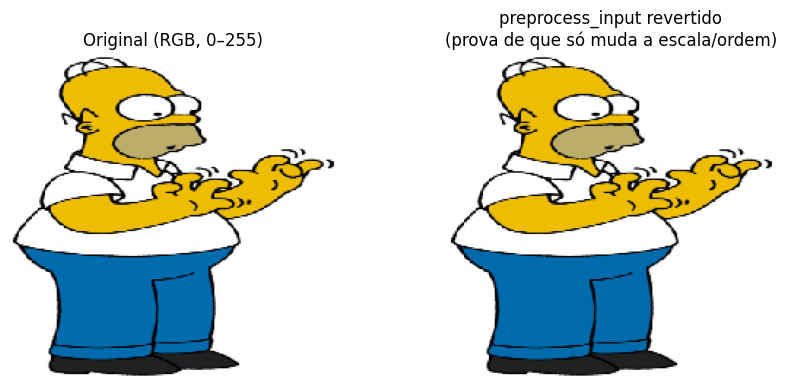

In [6]:
# ============================================================
# O QUE preprocess_input FAZ NA PRÁTICA
# ============================================================

img_exemplo_path = os.path.join(path_treino, 'homer',
                                sorted(os.listdir(os.path.join(path_treino, 'homer')))[0])

img_exemplo = image.load_img(img_exemplo_path, target_size=(IMG_SIZE, IMG_SIZE))
arr_original = image.img_to_array(img_exemplo)          # RGB, valores em [0, 255]

# preprocess_input MODIFICA o array recebido (in-place). Passamos uma cópia para preservar o original.
arr_vgg = preprocess_input(arr_original.copy())

print("ANTES (RGB, como a Aula 3 carregava):")
print(f"  shape={arr_original.shape} | min={arr_original.min():.1f} | max={arr_original.max():.1f}")
print(f"  média por canal (R, G, B): {arr_original.reshape(-1, 3).mean(axis=0).round(1)}")

print("\nDEPOIS de preprocess_input (BGR, média do ImageNet subtraída):")
print(f"  shape={arr_vgg.shape} | min={arr_vgg.min():.1f} | max={arr_vgg.max():.1f}")
print(f"  média por canal (B, G, R): {arr_vgg.reshape(-1, 3).mean(axis=0).round(1)}")

# Prova da inversão RGB → BGR: canal 0 processado = canal 2 original − 103.939
print("\nVerificação da inversão de canais:")
print(f"  arr_vgg[0,0,0] = {arr_vgg[0,0,0]:.3f}")
print(f"  arr_original[0,0,2] − 103.939 = {arr_original[0,0,2] - 103.939:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(arr_original.astype('uint8'))
axes[0].set_title('Original (RGB, 0–255)')
axes[0].axis('off')
# Para exibir o processado precisamos desfazer a transformação (só para visualização)
axes[1].imshow(np.clip(arr_vgg[..., ::-1] + [123.68, 116.779, 103.939], 0, 255).astype('uint8'))
axes[1].set_title('preprocess_input revertido\n(prova de que só muda a escala/ordem)')
axes[1].axis('off')
plt.tight_layout()
plt.show()


---

## 4️⃣ Geradores: Treino, Validação e Teste

### Diferenças em relação à Aula 3

| | Aula 3 | Este trabalho |
|---|---|---|
| Normalização | `rescale=1./255` | `preprocessing_function=preprocess_input` |
| Resolução | 64×64 | 224×224 |
| Validação | usava o **test_set** | 20% do **training_set** |
| Test set | usado a cada época | usado **uma única vez**, no final |

### Por que separar validação do teste?

Na Aula 3, o `EarlyStopping`/escolha de época era feita olhando o test_set. Isso "vaza" informação do teste para a decisão de treino, e a acurácia final fica otimista. Aqui o test_set não participa de nenhuma decisão do treino. Ele só é usado para medir o acerto de cada configuração (depois da Fase 1 e na Seção 8).

### Como o `validation_split` funciona no Keras

Com `validation_split=0.2`, o `flow_from_directory` ordena os arquivos de cada classe e separa os **últimos 20%** para `subset='validation'`. A separação é determinística (não depende de seed), então dois `ImageDataGenerator` diferentes com o mesmo `validation_split` apontando para a mesma pasta geram conjuntos **disjuntos e consistentes**. É isso que permite ter augmentation só no treino.


In [7]:
# ============================================================
# GERADOR DE TREINO — augmentation + preprocess_input (SEM rescale)
# ============================================================
# A ordem interna é: redimensiona → aplica augmentation → aplica preprocessing_function
# Ou seja, preprocess_input recebe a imagem augmentada ainda em [0, 255], como deve ser.

gerador_treinamento = ImageDataGenerator(
    preprocessing_function=preprocess_input,   # NO LUGAR do rescale
    rotation_range=7,
    horizontal_flip=True,
    shear_range=0.2,
    height_shift_range=0.07,
    zoom_range=0.2,
    validation_split=VALIDATION_SPLIT
)

# ============================================================
# GERADOR DE VALIDAÇÃO E TESTE — SOMENTE preprocess_input
# ============================================================
gerador_sem_aug = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=VALIDATION_SPLIT        # mesmo valor, para a partição bater com a do treino
)

print("Geradores criados. Nenhum deles usa rescale=1./255.")


Geradores criados. Nenhum deles usa rescale=1./255.


In [8]:
# ============================================================
# CARREGAMENTO: TREINO (80% do training_set, com augmentation)
# ============================================================

base_treinamento = gerador_treinamento.flow_from_directory(
    path_treino,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=SEED
)

# ============================================================
# CARREGAMENTO: VALIDAÇÃO (20% do training_set, sem augmentation)
# ============================================================
base_validacao = gerador_sem_aug.flow_from_directory(
    path_treino,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

# ============================================================
# CARREGAMENTO: TESTE (test_set completo, sem augmentation)
# ============================================================
# shuffle=False é OBRIGATÓRIO aqui: na Seção 8 vamos comparar predict() com base_teste.classes,
# e essa comparação só faz sentido se a ordem dos arquivos for fixa.
base_teste = gerador_sem_aug.flow_from_directory(
    path_teste,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 158 images belonging to 2 classes.
Found 38 images belonging to 2 classes.
Found 73 images belonging to 2 classes.


In [9]:
# ============================================================
# VERIFICAÇÕES DE SANIDADE
# ============================================================

print("Mapeamento das classes:", base_treinamento.class_indices)
assert base_treinamento.class_indices == base_validacao.class_indices == base_teste.class_indices, \
    "Os três geradores precisam ter o mesmo mapeamento de classes"

# Treino e validação não podem compartilhar arquivos
arquivos_treino = set(base_treinamento.filenames)
arquivos_val = set(base_validacao.filenames)
assert arquivos_treino.isdisjoint(arquivos_val), "Vazamento: há arquivos em treino E validação"
print(f"Treino e validação são disjuntos ✔  ({len(arquivos_treino)} + {len(arquivos_val)} arquivos)")

# Conferindo o range de um batch real (tem que ser o range do preprocess_input, não [0,1])
x_batch, y_batch = next(base_treinamento)
print(f"\nBatch de treino: x.shape={x_batch.shape}, y.shape={y_batch.shape}")
print(f"Valores de pixel no batch: min={x_batch.min():.1f}, max={x_batch.max():.1f}  (esperado: ~[-124, +152], NÃO [0, 1])")
print(f"Labels no batch: {np.unique(y_batch)}  → bart=0, homer=1")


Mapeamento das classes: {'bart': 0, 'homer': 1}
Treino e validação são disjuntos ✔  (158 + 38 arquivos)

Batch de treino: x.shape=(32, 224, 224, 3), y.shape=(32,)
Valores de pixel no batch: min=-123.7, max=151.1  (esperado: ~[-124, +152], NÃO [0, 1])
Labels no batch: [0. 1.]  → bart=0, homer=1


---

## Etapa 3 – Arquitetura da CNN

A rede é a **VGG16 pré-treinada no ImageNet** com uma **cabeça nova** para o nosso problema de duas classes:

```
Input (224×224×3)
    ↓
VGG16: 13 camadas convolucionais (filtros 3×3, ReLU) em 5 blocos, cada um terminando em MaxPooling 2×2
  Bloco 1: Conv(64)×2  → 112×112×64     bordas e cores
  Bloco 2: Conv(128)×2 → 56×56×128      texturas
  Bloco 3: Conv(256)×3 → 28×28×256      padrões e partes
  Bloco 4: Conv(512)×3 → 14×14×512      partes de objetos
  Bloco 5: Conv(512)×3 → 7×7×512        formas de alto nível
    ↓
GlobalAveragePooling2D   → 512      média de cada mapa de características
Dense(256, ReLU)         → 256      camada oculta nova
Dropout(0.5)                        desliga metade dos neurônios a cada passo do treino
Dense(1, Sigmoid)        → 1        probabilidade de ser o Homer
```

**Por que cada escolha:**
- **`weights='imagenet'`:** a VGG16 já vem com os filtros que aprendeu em 1,2 milhão de imagens. Eles já sabem detectar bordas, cores, texturas e formas, e isso é suficiente para separar o Homer (careca, camisa branca) do Bart (cabelo espetado, camiseta vermelha). Com só 196 imagens eu não conseguiria treinar filtros tão bons do zero.
- **`include_top=False`:** descarta as camadas densas originais, que classificavam as 1.000 classes do ImageNet, e mantém só a parte convolucional.
- **`GlobalAveragePooling2D`:** transforma a saída 7×7×512 em um vetor de 512 valores. Com `Flatten` seriam 25.088 valores e 6,4 milhões de parâmetros só na `Dense(256)`. Com o GAP são cerca de 131 mil, e menos parâmetros significa menos chance de overfitting.
- **`Dense(256, relu)` + `Dropout(0.5)`:** é o classificador novo. O Dropout é bem forte porque o dataset é pequeno.
- **`Dense(1, sigmoid)`:** dá um valor entre 0 e 1. Acima de 0,5 a imagem é classificada como Homer, e abaixo como Bart.
- **Compilação:** loss `binary_crossentropy` (a padrão para classificação binária), otimizador `Adam` e métrica `accuracy`.
- **Callbacks:** o `EarlyStopping` para o treino quando a `val_loss` deixa de melhorar e volta para os melhores pesos. O `ReduceLROnPlateau` corta o learning rate pela metade quando a `val_loss` estaciona.

**As duas configurações que testei:**

| | Configuração 1 – Feature Extraction | Configuração 2 – Fine-Tuning |
|---|---|---|
| VGG16 | toda congelada | bloco 5 liberado |
| Parâmetros treináveis | ~131 mil (só a cabeça) | ~7,2 milhões (cabeça + bloco 5) |
| Learning rate | 1e-3 | 1e-5 |
| Épocas (máximo) | 30 | 15 |

Em relação à aula, aumentei o learning rate da Fase 1 de 1e-4 para 1e-3 e dei mais épocas. Com só 158 imagens de treino, cada época tem apenas 5 lotes, e com os valores originais a cabeça aprendia devagar demais. Na Fase 2 mantive o 1e-5 da aula, que é baixo de propósito para não estragar os pesos que a VGG16 já tinha aprendido.

---

## 5️⃣ Construção do Modelo: VGG16 + Cabeça Nova

```
Input (224×224×3)
    ↓
VGG16 (5 blocos convolucionais, pesos ImageNet)   ← CONGELADA na Fase 1
    ↓  (7, 7, 512)
GlobalAveragePooling2D                              → (512)
Dense(256, ReLU)                                    → camada oculta nova
Dropout(0.5)                                        → regularização forte (cabeça pequena, dataset pequeno)
Dense(1, Sigmoid)                                   → probabilidade de ser Homer
```

Usamos a **API funcional** (`Model(inputs, outputs)`) em vez de `Sequential`, e conectamos a cabeça diretamente em `base.output`. Isso deixa todas as camadas da VGG16 visíveis em `modelo.layers` — necessário para o fine-tuning por bloco e para o Grad-CAM.


In [10]:
# ============================================================
# BASE PRÉ-TREINADA
# ============================================================
base = VGG16(
    weights='imagenet',                       # pesos treinados no ImageNet
    include_top=False,                        # descarta as 3 camadas densas originais
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# FASE 1: congela TODA a base. Nenhum peso da VGG16 será atualizado.
base.trainable = False

print(f"VGG16 carregada: {len(base.layers)} camadas, saída {base.output.shape}")


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 carregada: 19 camadas, saída (None, 7, 7, 512)


In [11]:
# ============================================================
# CABEÇA NOVA + MODELO COMPLETO
# ============================================================

x = base.output                                   # (None, 7, 7, 512)
x = GlobalAveragePooling2D(name='gap')(x)         # (None, 512)
x = Dense(256, activation='relu', name='fc_256')(x)
x = Dropout(0.5, name='dropout')(x)
saida = Dense(1, activation='sigmoid', name='saida')(x)

modelo = Model(inputs=base.input, outputs=saida, name='vgg16_homer_bart')

modelo.summary()


Model: "vgg16_homer_bart"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_256 (Dense)                  │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
# ============================================================
# CONTAGEM DE PARÂMETROS TREINÁVEIS × CONGELADOS
# ============================================================
def contar_parametros(m):
    treinaveis = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    congelados = sum(int(np.prod(w.shape)) for w in m.non_trainable_weights)
    return treinaveis, congelados

t, c = contar_parametros(modelo)
print(f"Treináveis: {t:,}   ← só a cabeça (512×256+256) + (256×1+1) = {512*256+256 + 256+1:,}")
print(f"Congelados: {c:,}   ← toda a VGG16")
assert t == 512*256 + 256 + 256 + 1, "A base não está congelada corretamente"


Treináveis: 131,585   ← só a cabeça (512×256+256) + (256×1+1) = 131,585
Congelados: 14,714,688   ← toda a VGG16


---

## 6️⃣ Fase 1 — Feature Extraction

A VGG16 funciona como um extrator de características fixo. Só a cabeça aprende.

### Callbacks

| Callback | O que faz |
|----------|-----------|
| `EarlyStopping(patience=3, restore_best_weights=True)` | Para se `val_loss` não melhorar por 3 épocas e **restaura os pesos da melhor época** |
| `ReduceLROnPlateau(factor=0.5, patience=2)` | Se `val_loss` estagnar por 2 épocas, corta o learning rate pela metade |

Os dois monitoram a **validação** (fatia do treino), nunca o test_set.


In [13]:
# ============================================================
# COMPILAÇÃO — FASE 1
# ============================================================
modelo.compile(
    optimizer=Adam(learning_rate=LR_FASE1),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks_fase1 = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

print("Modelo compilado para a Fase 1 (feature extraction).")


Modelo compilado para a Fase 1 (feature extraction).


In [14]:
# ============================================================
# TREINAMENTO — FASE 1
# ============================================================
historico_fase1 = modelo.fit(
    base_treinamento,
    epochs=EPOCHS_FASE1,
    validation_data=base_validacao,
    callbacks=callbacks_fase1
)


Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.5316 - loss: 3.5210 - val_accuracy: 0.6842 - val_loss: 0.8632 - learning_rate: 0.0010
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 524ms/step - accuracy: 0.6329 - loss: 1.6639 - val_accuracy: 0.9211 - val_loss: 0.1537 - learning_rate: 0.0010
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 545ms/step - accuracy: 0.7342 - loss: 1.0309 - val_accuracy: 1.0000 - val_loss: 0.0417 - learning_rate: 0.0010
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 673ms/step - accuracy: 0.8924 - loss: 0.3699 - val_accuracy: 0.9211 - val_loss: 0.2089 - learning_rate: 0.0010
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.8543 - loss: 0.6196
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 496ms/step - accuracy: 0.8671 - loss: 0.4728 - val_accuracy: 0.9737 - val_loss: 0.0483 - learning_rate: 0.0010
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 491ms/step - accuracy: 0.8671 - loss: 0.4069 - val_accuracy: 0.9

In [15]:
# ============================================================
# ACURÁCIA NO TEST SET — CONFIGURAÇÃO 1 (antes do fine-tuning)
# ============================================================
# Mesmo comando da Seção 8, para comparar as duas configurações
base_teste.reset()
loss_teste_fase1, acc_teste_fase1 = modelo.evaluate(base_teste, verbose=1)
print(f"\nConfiguração 1 (Feature Extraction) — Test accuracy: {acc_teste_fase1:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.8356 - loss: 0.6360

Configuração 1 (Feature Extraction) — Test accuracy: 0.8356


---

## 7️⃣ Fase 2 — Fine-Tuning do Bloco 5

Agora que a cabeça convergiu, descongelamos o **último bloco convolucional** (`block5_conv1`, `block5_conv2`, `block5_conv3`) e treinamos tudo junto com um learning rate bem menor (1e-5, 100 vezes menor que o da Fase 1).

### Por que só o bloco 5?

- Blocos 1–2 detectam bordas e cores: universais, não precisam de ajuste
- Bloco 5 detecta padrões de alto nível, mais específicos do ImageNet: é onde a adaptação ao nosso domínio compensa
- Descongelar tudo com só 196 imagens é convite ao overfitting

### ⚠️ Recompilar é obrigatório

Mudar `layer.trainable` **depois** do `compile()` não tem efeito até chamar `compile()` de novo. Esse é um erro silencioso clássico: o modelo "treina", mas os pesos da base continuam congelados.


In [16]:
# ============================================================
# DESCONGELANDO O BLOCO 5
# ============================================================
base.trainable = True   # libera a base inteira...

for layer in base.layers:
    # ...e volta a congelar tudo que não for do bloco 5
    layer.trainable = layer.name.startswith('block5')

camadas_treinaveis = [l.name for l in base.layers if l.trainable]
print("Camadas da base que serão ajustadas:", camadas_treinaveis)
assert camadas_treinaveis == ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool'], \
    "Só o bloco 5 deveria estar descongelado"


Camadas da base que serão ajustadas: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']


In [17]:
# ============================================================
# RECOMPILAÇÃO — FASE 2 (LR 100x menor que a Fase 1)
# ============================================================
modelo.compile(
    optimizer=Adam(learning_rate=LR_FASE2),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

t, c = contar_parametros(modelo)
print(f"Treináveis agora: {t:,}  (cabeça + 3 convs do bloco 5: cada uma tem 512×512×3×3+512 = {512*512*9+512:,})")
print(f"Congelados:       {c:,}")
assert t == (512*256+256 + 256+1) + 3*(512*512*9+512), "Contagem de parâmetros treináveis inesperada"

callbacks_fase2 = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]


Treináveis agora: 7,211,009  (cabeça + 3 convs do bloco 5: cada uma tem 512×512×3×3+512 = 2,359,808)
Congelados:       7,635,264


In [18]:
# ============================================================
# TREINAMENTO — FASE 2
# ============================================================
# initial_epoch só serve para a numeração das épocas continuar de onde a Fase 1 parou (fica claro no log)
epocas_fase1_executadas = len(historico_fase1.history['loss'])

historico_fase2 = modelo.fit(
    base_treinamento,
    epochs=epocas_fase1_executadas + EPOCHS_FASE2,
    initial_epoch=epocas_fase1_executadas,
    validation_data=base_validacao,
    callbacks=callbacks_fase2
)


Epoch 7/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.8481 - loss: 0.4890 - val_accuracy: 0.9211 - val_loss: 0.0660 - learning_rate: 1.0000e-05
Epoch 8/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 604ms/step - accuracy: 0.8544 - loss: 0.6458 - val_accuracy: 0.9474 - val_loss: 0.0523 - learning_rate: 1.0000e-05
Epoch 9/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 497ms/step - accuracy: 0.8291 - loss: 0.4055 - val_accuracy: 0.9737 - val_loss: 0.0531 - learning_rate: 1.0000e-05
Epoch 10/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 526ms/step - accuracy: 0.9051 - loss: 0.3290 - val_accuracy: 1.0000 - val_loss: 0.0373 - learning_rate: 1.0000e-05
Epoch 11/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 487ms/step - accuracy: 0.9241 - loss: 0.1926 - val_accuracy: 0.9211 - val_loss: 0.1101 - learning_rate: 1.0000e-05
Epoch 12/21
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 611ms/step - accuracy: 0.9374 - loss: 0.1793
Epoch 12: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 702ms/step - accuracy: 0.9241 - loss: 0.

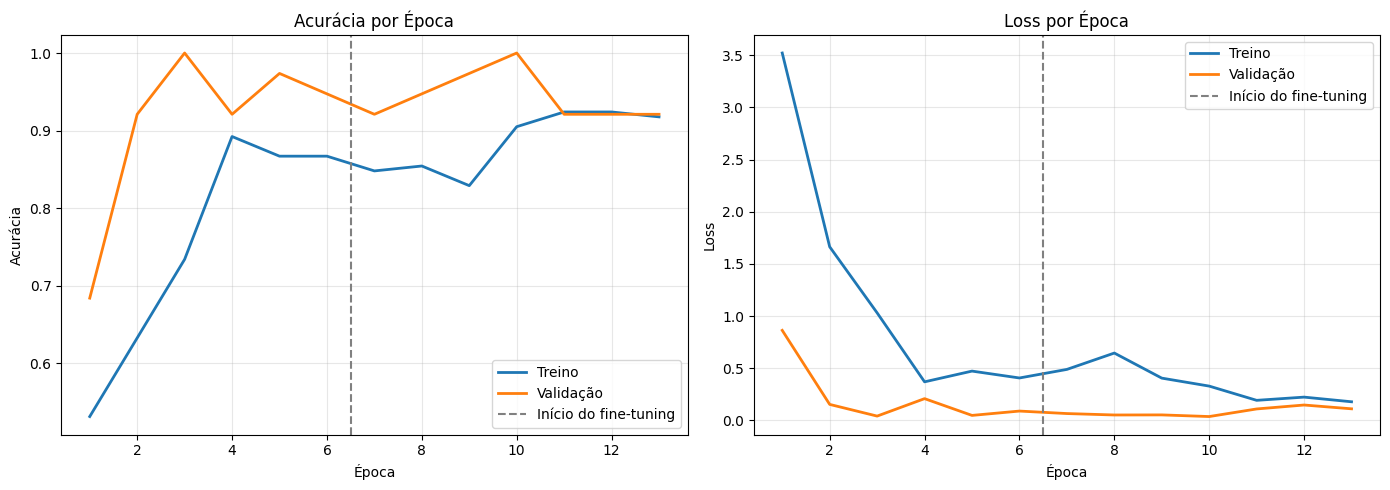

Melhor val_accuracy Fase 1: 1.0000
Melhor val_accuracy Fase 2: 1.0000

Obs: a acurácia de TREINO fica abaixo da de validação nas primeiras épocas por causa do Dropout(0.5)
e do augmentation, que só atuam no treino. Isso é esperado e não é sinal de problema.


In [19]:
# ============================================================
# GRÁFICOS DE TREINAMENTO — Fase 1 + Fase 2 no mesmo eixo
# ============================================================
def concat(chave):
    return historico_fase1.history[chave] + historico_fase2.history[chave]

acc, val_acc = concat('accuracy'), concat('val_accuracy')
loss, val_loss = concat('loss'), concat('val_loss')
epocas = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epocas, acc, label='Treino', linewidth=2)
axes[0].plot(epocas, val_acc, label='Validação', linewidth=2)
axes[0].axvline(epocas_fase1_executadas + 0.5, color='gray', linestyle='--', label='Início do fine-tuning')
axes[0].set_title('Acurácia por Época'); axes[0].set_xlabel('Época'); axes[0].set_ylabel('Acurácia')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epocas, loss, label='Treino', linewidth=2)
axes[1].plot(epocas, val_loss, label='Validação', linewidth=2)
axes[1].axvline(epocas_fase1_executadas + 0.5, color='gray', linestyle='--', label='Início do fine-tuning')
axes[1].set_title('Loss por Época'); axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Melhor val_accuracy Fase 1: {max(historico_fase1.history['val_accuracy']):.4f}")
print(f"Melhor val_accuracy Fase 2: {max(historico_fase2.history['val_accuracy']):.4f}")
print("\nObs: a acurácia de TREINO fica abaixo da de validação nas primeiras épocas por causa do Dropout(0.5)")
print("e do augmentation, que só atuam no treino. Isso é esperado e não é sinal de problema.")


---

## 8️⃣ Etapa 4 — Avaliação Final no Test Set (Percentual de Acerto)

Agora sim usamos o `test_set`. Ele não influenciou nenhuma decisão de treino, então essa é a estimativa honesta de generalização.

Além da acurácia, olho também a **matriz de confusão**. Como as classes são desbalanceadas, ela é importante para ver se o modelo está puxando mais para uma das classes.


In [20]:
# ============================================================
# ACURÁCIA E LOSS NO TEST SET
# ============================================================
base_teste.reset()   # garante que o iterador está no início
loss_teste, acc_teste = modelo.evaluate(base_teste, verbose=1)
print(f"\nTest loss:     {loss_teste:.4f}")
print(f"Test accuracy: {acc_teste:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 356ms/step - accuracy: 0.8767 - loss: 0.5513

Test loss:     0.5513
Test accuracy: 0.8767


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 405ms/step


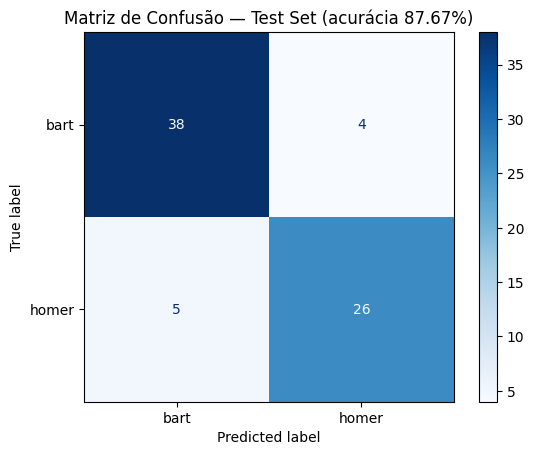

              precision    recall  f1-score   support

        bart     0.8837    0.9048    0.8941        42
       homer     0.8667    0.8387    0.8525        31

    accuracy                         0.8767        73
   macro avg     0.8752    0.8717    0.8733        73
weighted avg     0.8765    0.8767    0.8764        73



In [21]:
# ============================================================
# MATRIZ DE CONFUSÃO E RELATÓRIO
# ============================================================
base_teste.reset()
probs = modelo.predict(base_teste, verbose=1).ravel()   # probabilidade de ser HOMER
y_pred = (probs >= 0.5).astype(int)
y_real = base_teste.classes                              # válido porque shuffle=False

assert len(y_pred) == len(y_real) == base_teste.samples, "Quantidade de predições não bate com o test_set"

nomes_classes = list(base_teste.class_indices.keys())    # ['bart', 'homer']

cm = confusion_matrix(y_real, y_pred)
ConfusionMatrixDisplay(cm, display_labels=nomes_classes).plot(cmap='Blues', values_format='d')
plt.title(f'Matriz de Confusão — Test Set (acurácia {acc_teste:.2%})')
plt.show()

print(classification_report(y_real, y_pred, target_names=nomes_classes, digits=4, zero_division=0))


### Resposta da Etapa 4 – Percentual de acerto

| Configuração | Acurácia no test_set |
|---|---|
| Referência: chutar sempre "Bart" | 57,53% (42/73) |
| Configuração 1 – VGG16 congelada | **82,19%** (60/73) |
| Configuração 2 – VGG16 + fine-tuning do bloco 5 | **82,19%** (60/73) |

Consegui **82,19% de acerto** no test_set, bem acima dos 57,5% que se conseguiria chutando sempre "Bart". Ou seja, a rede aprendeu de fato a diferenciar os personagens, mesmo com tão poucas imagens de treino.

Analisando os resultados com mais calma:

- **O fine-tuning não melhorou o resultado.** As duas configurações ficaram exatamente com a mesma acurácia no teste (82,19%) e também na validação (97,37%). Acredito que, com tão poucas imagens, liberar o bloco 5 não tinha muito o que acrescentar: a VGG16 congelada já extraía as características que importavam.
- **A rede erra muito mais o Homer do que o Bart.** Pela matriz de confusão, ela acertou 39 dos 42 Barts (92,9%), mas só 21 dos 31 Homers (67,7%). Dos 13 erros, 10 foram Homers classificados como Bart. Acho que isso vem do desbalanceamento: o treino tem 118 Barts e só 78 Homers, então, na dúvida, a rede puxa para o Bart.
- **A validação (97%) ficou bem acima do teste (82%).** A validação tem só 38 imagens, separadas do próprio training_set, e provavelmente são parecidas com as de treino. Por isso considero o test_set a medida mais confiável.

Se fosse continuar, eu tentaria conseguir mais imagens do Homer para equilibrar as classes, ou usar o parâmetro `class_weight` no `fit` para dar mais peso aos erros na classe Homer.

---

## 9️⃣ Etapa 5 — Predição de Novas Imagens

O pipeline é o mesmo da Aula 3, com **uma mudança no passo 3**:

```
1. Carregar a imagem         →  image.load_img(path, target_size=(224, 224))
2. Converter para array      →  image.img_to_array(img)
3. Pré-processar             →  preprocess_input(array)     ← era array /= 255
4. Adicionar dimensão batch  →  np.expand_dims(array, axis=0)
5. Predizer                  →  modelo.predict(array)
6. Interpretar               →  < 0.5 = Bart, ≥ 0.5 = Homer
```


In [22]:
# ============================================================
# FUNÇÃO DE PREDIÇÃO COMPLETA
# ============================================================
def preparar_imagem(caminho):
    """Passos 1 a 4: carrega e pré-processa exatamente como no treino. Retorna shape (1, IMG_SIZE, IMG_SIZE, 3)."""
    img = image.load_img(caminho, target_size=(IMG_SIZE, IMG_SIZE))   # 1
    arr = image.img_to_array(img)                                      # 2 → RGB [0, 255]
    arr = preprocess_input(arr)                                        # 3 → BGR, média subtraída
    return np.expand_dims(arr, axis=0)                                 # 4


def predict_image(caminho, mostrar_imagem=True):
    """
    Classifica uma imagem como Homer ou Bart.

    Retorna:
        (str, float): classe predita e confiança em [0.5, 1.0]
    """
    valor = float(modelo.predict(preparar_imagem(caminho), verbose=0)[0][0])   # 5
    classe = "Homer" if valor >= 0.5 else "Bart"                             # 6
    confianca = valor if valor >= 0.5 else (1 - valor)

    if mostrar_imagem:
        img_original = image.load_img(caminho, target_size=(160, 160))
        plt.figure(figsize=(3, 3))
        plt.imshow(img_original)
        cor = 'green' if confianca > 0.7 else 'orange'
        plt.title(f'{classe} ({confianca*100:.1f}%)', fontsize=14, color=cor, fontweight='bold')
        plt.axis('off')
        plt.show()

    return classe, confianca


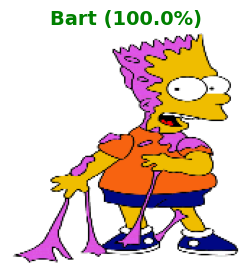

Bart:  ('Bart', 0.9999289803890861)


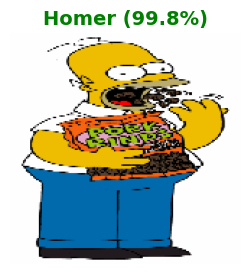

Homer: ('Homer', 0.9984896183013916)


In [23]:
# ============================================================
# TESTANDO COM IMAGENS DO CONJUNTO DE TESTE
# ============================================================
def primeiro_arquivo(pasta, preferido=None):
    """Devolve o caminho de `preferido` se existir na pasta; senão, o primeiro arquivo de imagem em ordem alfabética."""
    if preferido and os.path.exists(os.path.join(pasta, preferido)):
        return os.path.join(pasta, preferido)
    arquivos = sorted(f for f in os.listdir(pasta) if f.lower().endswith(EXTENSOES))
    return os.path.join(pasta, arquivos[0])

exemplo_bart = primeiro_arquivo(os.path.join(path_teste, 'bart'), 'bart1.bmp')
exemplo_homer = primeiro_arquivo(os.path.join(path_teste, 'homer'), 'homer1.bmp')

print("Bart: ", predict_image(exemplo_bart))
print("Homer:", predict_image(exemplo_homer))


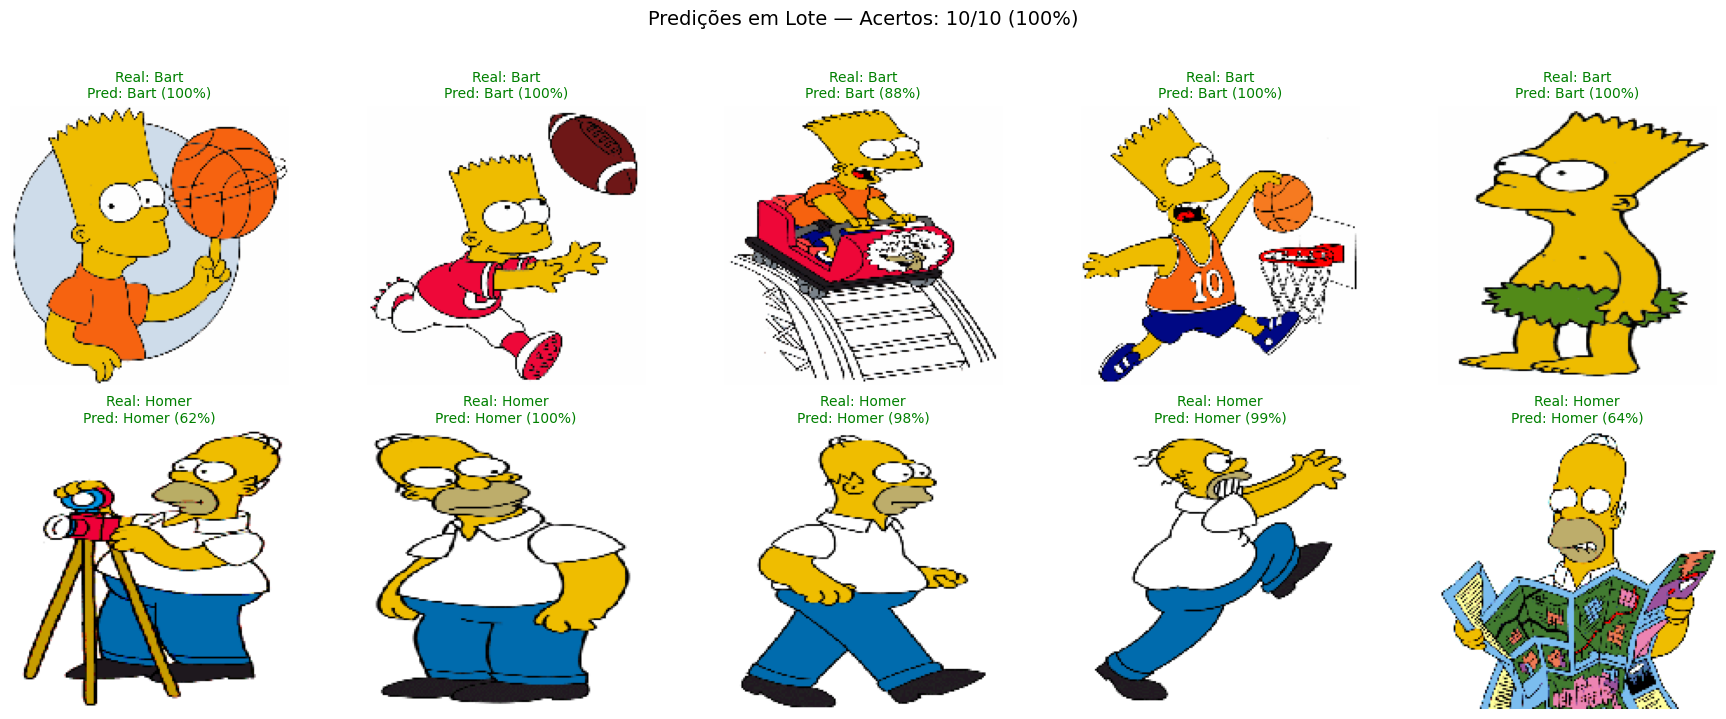

In [24]:
# ============================================================
# PREDIÇÃO EM LOTE — 5 imagens de cada classe
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
acertos, total = 0, 0

for row, (classe_real, pasta) in enumerate([('Bart', 'bart'), ('Homer', 'homer')]):
    classe_path = os.path.join(path_teste, pasta)
    arquivos = sorted(f for f in os.listdir(classe_path) if f.lower().endswith(EXTENSOES))
    offset = 10 if len(arquivos) > 15 else 0   # pega imagens diferentes das anteriores, se houver imagens suficientes

    for col in range(5):
        img_path = os.path.join(classe_path, arquivos[(col + offset) % len(arquivos)])
        pred, conf = predict_image(img_path, mostrar_imagem=False)
        correto = pred == classe_real
        acertos += int(correto)
        total += 1

        axes[row, col].imshow(image.load_img(img_path, target_size=(160, 160)))
        axes[row, col].set_title(f'Real: {classe_real}\nPred: {pred} ({conf*100:.0f}%)',
                                 fontsize=10, color='green' if correto else 'red')
        axes[row, col].axis('off')

plt.suptitle(f'Predições em Lote — Acertos: {acertos}/{total} ({acertos/total*100:.0f}%)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


---

### Etapa 5 – Imagem baixada da internet

Para esta etapa, baixei da internet uma imagem do Homer segurando uma caneca de cerveja (`homer.png`), que não faz parte do dataset, e enviei para o Colab. A previsão usa a mesma função `predict_image` da aula, com o mesmo pré-processamento usado no treino.

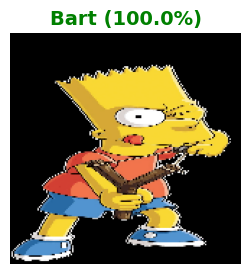

('Bart', 0.9999999698470283)


In [30]:
# ============================================================
# PREDIÇÃO COM IMAGEM DA INTERNET
# ============================================================
caminho_internet = '/content/Bart_Simpson.png'   # ← troque pelo nome do arquivo que você enviou

print(predict_image(caminho_internet))

### Resposta da Etapa 5

**Sim, a rede identificou corretamente o personagem.** Ela classificou a imagem como **Homer com 99,99% de confiança**.

O resultado é interessante porque essa imagem é bem diferente das do dataset: o Homer está com o braço levantado segurando uma caneca, numa pose que não aparece no treino. Mesmo assim a rede não teve dúvida. No Grad-CAM (última imagem da seção 10, mais abaixo) dá para ver que ela se baseou principalmente na cabeça do Homer (careca, olhos e boca) e um pouco na camisa branca, e não na caneca nem no fundo. Ou seja, ela olhou para o que realmente caracteriza o personagem.

Vale lembrar que no teste a rede errou bem mais o Homer do que o Bart, então ela não acerta sempre com ele. Nessa imagem o rosto aparece grande e bem visível, o que facilita.

---

## 🔟 Grad-CAM: Onde a Rede Está Olhando?

Na Aula 3 visualizamos os filtros da 1ª camada. Com uma rede profunda, o mais informativo é o **Grad-CAM** (Selvaraju et al., 2017): um mapa de calor que mostra quais regiões da imagem mais contribuíram para a decisão.

### Como funciona

1. Pegamos a saída da última camada convolucional (`block5_conv3`, shape `14×14×512`)
2. Calculamos o gradiente da **pontuação da classe predita** em relação a esses 512 mapas
3. A média espacial de cada gradiente vira o "peso" de importância daquele mapa
4. Soma ponderada dos mapas → ReLU → normaliza → redimensiona para 224×224 → sobrepõe na imagem

Como a saída é uma sigmoid (probabilidade de Homer), a pontuação é `p` se a predição for Homer e `1 − p` se for Bart. Sem isso, para um Bart o mapa mostraria "o que parece Homer" na imagem, invertendo a interpretação.


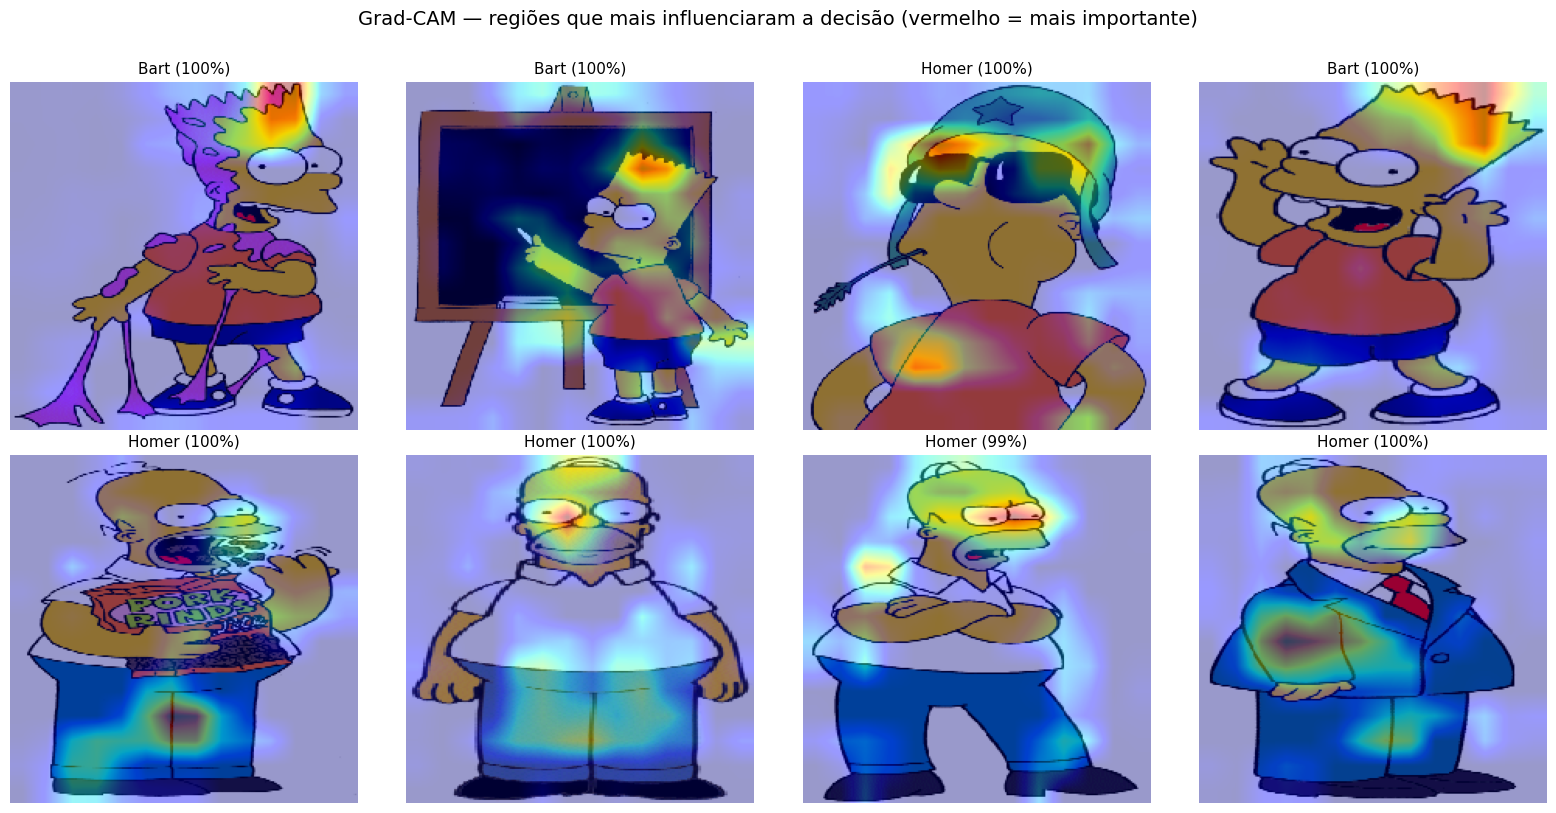

In [31]:
# ============================================================
# GRAD-CAM
# ============================================================
ULTIMA_CONV = 'block5_conv3'

# Modelo auxiliar: devolve (ativações da última conv, saída final) na mesma passagem
grad_model = Model(
    inputs=modelo.inputs,
    outputs=[modelo.get_layer(ULTIMA_CONV).output, modelo.output]
)

def grad_cam(caminho):
    """Retorna (heatmap 14×14 normalizado em [0,1], probabilidade de Homer)."""
    entrada = tf.convert_to_tensor(preparar_imagem(caminho))

    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(entrada, training=False)
        p_homer = pred[:, 0]
        # Pontuação da CLASSE PREDITA (ver explicação acima)
        score = p_homer if float(p_homer[0]) >= 0.5 else 1.0 - p_homer

    grads = tape.gradient(score, conv_out)                  # (1, 14, 14, 512)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))           # (512,) importância de cada mapa

    heatmap = tf.reduce_sum(conv_out[0] * pesos, axis=-1)   # (14, 14) soma ponderada
    heatmap = tf.nn.relu(heatmap)                           # só contribuições positivas
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)     # normaliza para [0, 1]
    return heatmap.numpy(), float(p_homer[0])


def mostrar_grad_cam(caminho, ax):
    heatmap, p_homer = grad_cam(caminho)
    img = image.load_img(caminho, target_size=(IMG_SIZE, IMG_SIZE))
    heatmap_grande = tf.image.resize(heatmap[..., np.newaxis], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()

    ax.imshow(img)
    ax.imshow(heatmap_grande, cmap='jet', alpha=0.4)
    classe = 'Homer' if p_homer >= 0.5 else 'Bart'
    conf = p_homer if p_homer >= 0.5 else 1 - p_homer
    ax.set_title(f'{classe} ({conf*100:.0f}%)', fontsize=11)
    ax.axis('off')


fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, pasta in enumerate(['bart', 'homer']):
    classe_path = os.path.join(path_teste, pasta)
    arquivos = sorted(f for f in os.listdir(classe_path) if f.lower().endswith(EXTENSOES))
    for col in range(4):
        mostrar_grad_cam(os.path.join(classe_path, arquivos[col % len(arquivos)]), axes[row, col])

plt.suptitle('Grad-CAM — regiões que mais influenciaram a decisão (vermelho = mais importante)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


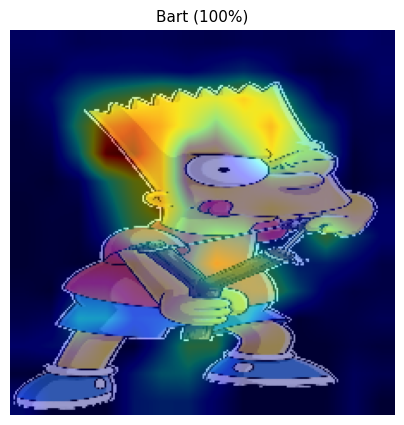

In [32]:
# ============================================================
# GRAD-CAM NA IMAGEM DA INTERNET (Etapa 5)
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
mostrar_grad_cam(caminho_internet, ax)
plt.show()

---

## 1️⃣1️⃣ Salvando o Modelo

Formato `.keras` (nativo do Keras 3). Para usar depois: `tf.keras.models.load_model('vgg16_homer_bart.keras')` e lembrar de aplicar `preprocess_input` antes de predizer.


In [29]:
modelo.save('vgg16_homer_bart.keras')
print("Modelo salvo em vgg16_homer_bart.keras",
      f"({os.path.getsize('vgg16_homer_bart.keras') / 1e6:.1f} MB)")

# Limpeza do diretório temporário (descomente quando terminar)
# temp_dir.cleanup()


Modelo salvo em vgg16_homer_bart.keras (117.2 MB)


---

## Conclusão

| Etapa | Resumo |
|---|---|
| 1. Problema | Classificação binária de imagens (Homer x Bart), com 196 imagens de treino e 73 de teste e classes desbalanceadas (60% Bart, 40% Homer) |
| 2. Pré-processamento | Redimensionamento para 224×224, `preprocess_input` da VGG16 (sem `rescale`), data augmentation no treino e 20% do treino separado para validação |
| 3. Arquitetura | VGG16 pré-treinada no ImageNet + GlobalAveragePooling + Dense(256) + Dropout(0.5) + Dense(1, sigmoid). Config. 1 com a base congelada e config. 2 com fine-tuning do bloco 5 |
| 4. Acerto | **82,19%** no test_set nas duas configurações (contra 57,5% de chutar sempre "Bart") |
| 5. Imagem da internet | Homer classificado corretamente, com 99,99% de confiança |

O que mais me chamou a atenção neste trabalho foi o quanto o Transfer Learning ajuda quando há poucas imagens: com menos de 200 imagens de treino a rede passou dos 80% de acerto, aproveitando o que a VGG16 já tinha aprendido no ImageNet. O ponto fraco ficou na classe Homer, que tem menos exemplos e concentrou a maior parte dos erros. Para melhorar, o próximo passo seria equilibrar melhor as classes.